# E222 · Learning to select useful correspondences

## Fixed policies

3 paired seeds on the E221 archive and held-out tracks. Each update uses 32 raw images from 16 physical tracks. Every image appears once per view in all arms. Track swaps partners within each track, and Mixed swaps exactly half. All arms take 256 updates with matched augmentation seeds. Early Track and Late Track change pairing at +128. Training heads, optimizer, and initial backbone match within a seed.

| Split | Independent tracks |
| --- | --- |
| trunk | 60 |
| test | 114 |
| fit | 112 |
| evaluation | 62 |
| choice | 70 |

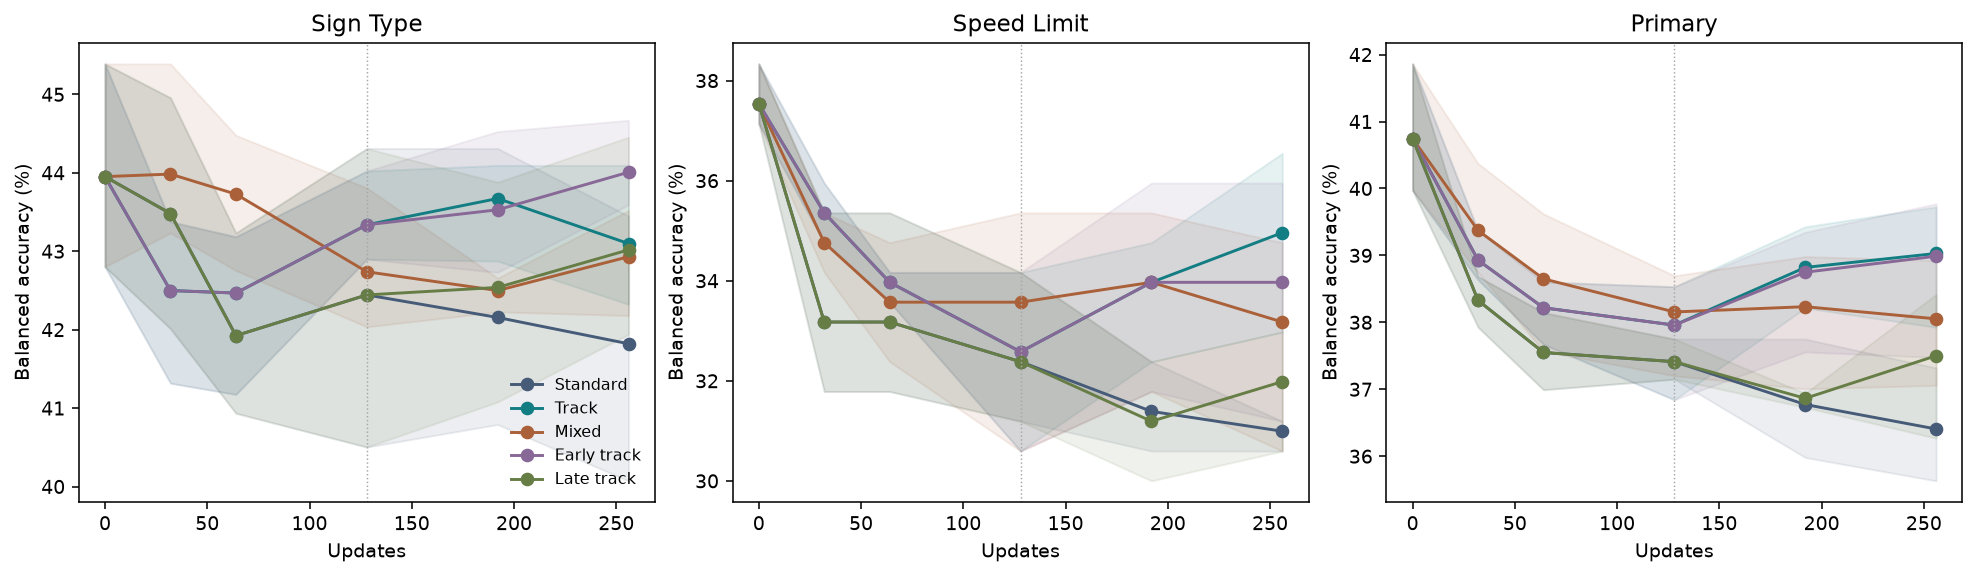

| Compared with Standard | Outcome | Mean early gain (pp) | Mean trajectory gain (pp) | Final seed gains (pp) |
| --- | --- | --- | --- | --- |
| Track | sign_type | +0.18 | +0.74 | +2.25, +2.16, -0.57 |
| Track | speed_limit | +0.89 | +1.61 | +5.36, +4.76, +1.79 |
| Track | primary | +0.54 | +1.18 | +3.80, +3.46, +0.61 |
| Mixed | sign_type | +0.88 | +0.70 | +3.45, +1.15, -1.27 |
| Mixed | speed_limit | +0.84 | +1.49 | -0.60, +4.17, +2.98 |
| Mixed | primary | +0.86 | +1.09 | +1.43, +2.66, +0.85 |
| Early track | sign_type | +0.18 | +0.82 | +3.69, +2.73, +0.14 |
| Early track | speed_limit | +0.89 | +1.49 | +0.00, +4.17, +4.76 |
| Early track | primary | +0.54 | +1.15 | +1.84, +3.45, +2.45 |
| Late track | sign_type | +0.00 | +0.25 | +2.59, +0.00, +1.01 |
| Late track | speed_limit | +0.00 | +0.07 | +1.79, +0.00, +1.19 |
| Late track | primary | +0.00 | +0.16 | +2.19, +0.00, +1.10 |

## Transfer and provenance

The BDD panel measures retention under sign adaptation. This study uses dataset-supplied physical identity for the positive pairs, so it is correspondence-supervised with class labels held out from optimization. The GTSRB dataset describes manual annotation as part of data construction. Natural driving transfer would require a separately verified causal tracker and evaluation on other objects. [GTSRB dataset paper](https://www.ini.rub.de/upload/file/1470692848_f03494010c16c36bab9e/StallkampEtAl_GTSRB_IJCNN2011.pdf)

| Policy | Mean BDD change (pp) |
| --- | --- |
| Standard | -0.05 |
| Track | -0.21 |
| Mixed | -0.04 |
| Early track | -0.02 |
| Late track | +0.02 |

## Difficulty and appearance agreement

Branches begin at +32 and +192 from the matching fixed Standard trajectory and use two independent continuation track pools. Every branch gets 32 updates. Short, medium and long lag groups use the same screened rule. Hard permissive uses all long-lag pairs. Hard random fallback uses the exact same frames and same number of cross-frame pairs per minibatch as Hard gated. Rejected slots become same-image positives. The confidence score is a fixed appearance cosine with a threshold fit on trunk tracks. It measures visual agreement among already supplied identities. It does not estimate real tracker precision.

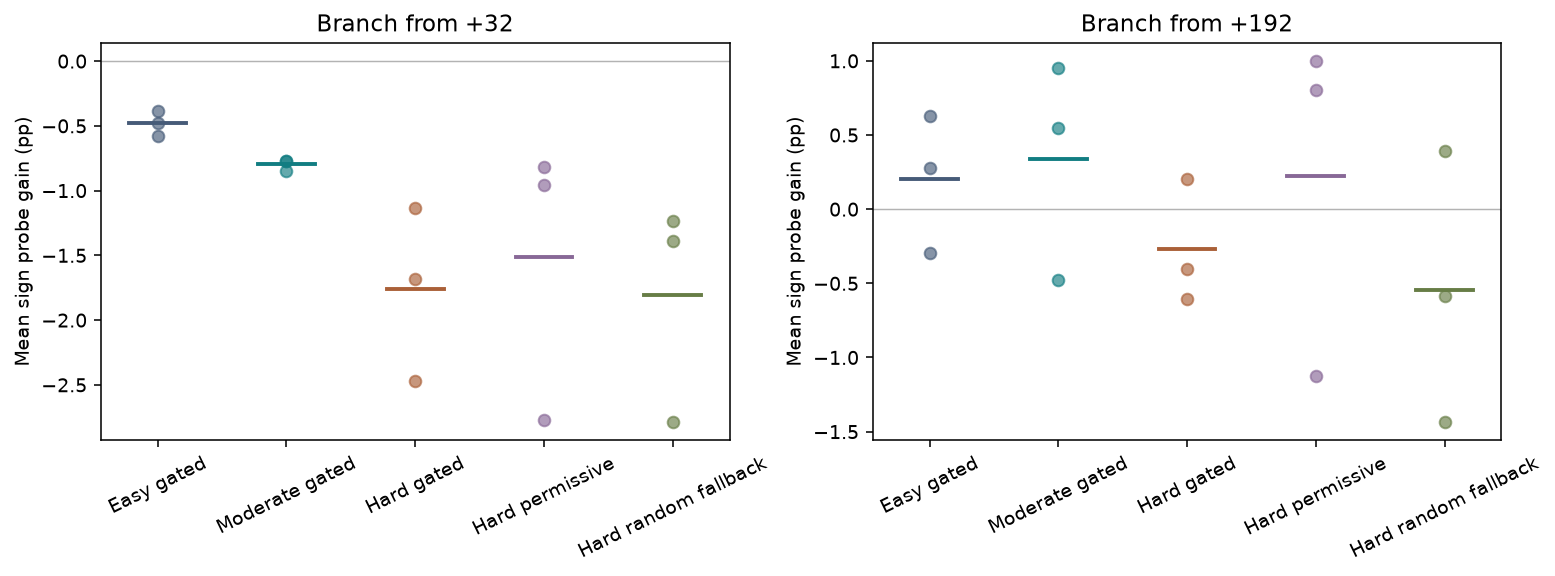

| Start | Action | Cross-frame share | Mean candidate lag | Mean accepted agreement |
| --- | --- | --- | --- | --- |
| 32 | Easy gated | 90.9% | 3.0 | 0.764 |
| 32 | Moderate gated | 76.7% | 7.5 | 0.682 |
| 32 | Hard gated | 51.5% | 14.5 | 0.610 |
| 32 | Hard permissive | 100.0% | 14.5 | 0.420 |
| 32 | Hard random fallback | 51.5% | 14.5 | 0.429 |
| 192 | Easy gated | 90.9% | 3.0 | 0.769 |
| 192 | Moderate gated | 77.1% | 7.5 | 0.684 |
| 192 | Hard gated | 53.1% | 14.5 | 0.607 |
| 192 | Hard permissive | 100.0% | 14.5 | 0.426 |
| 192 | Hard random fallback | 53.1% | 14.5 | 0.433 |

| Start | Policy | Sign-type gains (pp) | Speed-limit gains (pp) |
| --- | --- | --- | --- |
| 32 | Easy gated | -1.15, -1.36, +0.83 | +0.00, +0.60, -1.79 |
| 32 | Moderate gated | -2.30, -2.73, +0.54 | +0.60, +1.19, -2.08 |
| 32 | Hard gated | -2.27, -2.18, -1.36 | -0.00, -1.19, -3.57 |
| 32 | Hard permissive | -1.63, -3.40, -0.90 | -0.00, +1.49, -4.64 |
| 32 | Hard random fallback | -2.78, -2.18, -1.11 | -0.00, -0.30, -4.46 |

| Start | Policy | Sign-type gains (pp) | Speed-limit gains (pp) |
| --- | --- | --- | --- |
| 192 | Easy gated | +0.00, +1.15, -0.53 | -0.60, -0.60, +1.79 |
| 192 | Moderate gated | -0.36, +1.01, -0.99 | -0.60, +0.89, +2.08 |
| 192 | Hard gated | -0.22, +0.41, -1.21 | -0.60, +0.00, -0.00 |
| 192 | Hard permissive | -0.17, +1.01, -0.68 | -2.08, +0.60, +2.68 |
| 192 | Hard random fallback | -0.79, +1.08, -1.47 | -2.08, -0.30, +0.30 |

The hard-minus-easy advantage changed from early to late by **+0.45, +1.23, +0.75 pp** across the three seeds. Top-action agreement between draws was **0.0%**. Choosing on one draw and scoring on the other gained **-0.38, -0.63, -0.55 pp** over a fixed action selected on other seeds. The prospective control screen **did not pass**. These are retrospective choices using external probe outcomes.